# Stage 3: Neural Network

Feed-forward network (MLP) on the Stage 2 splits: baseline, hyperparameter tuning and training vs validation curves. Only train and validation data are used; the test set is not touched.

In [1]:
import ast
import copy
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

os.makedirs("../plots", exist_ok=True)
os.makedirs("../data", exist_ok=True)
os.makedirs("../models", exist_ok=True)

sns.set_theme(style="whitegrid")
TRAIN_C, VAL_C, MARK_C = "#2a78d6", "#eb6834", "#52514e"

## 1. Load the Stage 2 splits

In [2]:
DATA_DIR = next(d for d in ["../data/splits", "data/splits", "."] if os.path.exists(f"{d}/train.csv"))
TARGET = "Revenue"
train, val, test = (pd.read_csv(f"{DATA_DIR}/{n}.csv") for n in ("train", "val", "test"))

def split_xy(df):
    return df.drop(columns=[TARGET]), df[TARGET].astype(int).values

X_train, y_train = split_xy(train)
X_val, y_val = split_xy(val)

print(pd.DataFrame({"Rows": [len(train), len(val), len(test)],
                    "Purchase rate (%)": [round(100 * s[TARGET].mean(), 2) for s in (train, val, test)]},
                   index=["Train", "Validation", "Test"]).to_string())

            Rows  Purchase rate (%)
Train       8543              15.64
Validation  1831              15.62
Test        1831              15.62

## 2. Preprocessing

Same as Stage 2 (scaling + one-hot, fitted on train only), plus an optional `log1p` on 7 skewed columns that the search decides on.

In [3]:
CATEGORICAL = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
BINARY = ["Weekend"]
SKEWED = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
          "ProductRelated", "ProductRelated_Duration", "PageValues"]
OTHER_NUMERIC = ["BounceRates", "ExitRates", "SpecialDay"]

def make_preprocessor(log_skewed=False):
    cat = ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)
    if log_skewed:
        skew = Pipeline([("log", FunctionTransformer(np.log1p, validate=False)), ("sc", StandardScaler())])
        return ColumnTransformer([("skew", skew, SKEWED), ("num", StandardScaler(), OTHER_NUMERIC),
                                  cat, ("bin", "passthrough", BINARY)])
    return ColumnTransformer([("num", StandardScaler(), SKEWED + OTHER_NUMERIC),
                              cat, ("bin", "passthrough", BINARY)])

PREP = {log: make_preprocessor(log).fit(X_train) for log in (False, True)}
DATA = {log: (PREP[log].transform(X_train), PREP[log].transform(X_val)) for log in (False, True)}
print("Input features after encoding:", DATA[False][0].shape[1])

Input features after encoding: 73

## 3. Network and training functions

Adam optimiser, class-weighted log-loss, L2 penalty, early stopping on validation loss. Trained one epoch at a time to record the curves.

In [4]:
def class_sample_weights(y, mode="balanced"):
    if mode in (None, "none"):
        return np.ones(len(y))
    n = len(y)
    w1, w0 = n / (2.0 * y.sum()), n / (2.0 * (n - y.sum()))
    if mode == "sqrt":
        w1, w0 = np.sqrt(w1), np.sqrt(w0)
    return np.where(y == 1, w1, w0)

def weighted_log_loss(y, p, w):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return float(np.sum(w * -(y * np.log(p) + (1 - y) * np.log(1 - p))) / np.sum(w))

def metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, p)}

def new_mlp(hidden, activation, alpha, lr, batch_size, seed):
    return MLPClassifier(hidden_layer_sizes=hidden, activation=activation, solver="adam", alpha=alpha,
                         learning_rate_init=lr, batch_size=batch_size, shuffle=True, random_state=seed)

def train_mlp(Xtr, ytr, Xva, yva, hidden=(64, 32), activation="relu", alpha=1e-4, lr=1e-3, batch_size=128,
              class_weight="balanced", max_epochs=150, patience=15, early_stop=True, seed=RANDOM_STATE):
    mlp = new_mlp(hidden, activation, alpha, lr, batch_size, seed)
    w_tr, w_va = class_sample_weights(ytr, class_weight), class_sample_weights(yva, class_weight)
    rows, best, bad = [], (np.inf, None, 0), 0
    for ep in range(1, max_epochs + 1):
        mlp.partial_fit(Xtr, ytr, sample_weight=w_tr, classes=[0, 1])
        ptr, pva = mlp.predict_proba(Xtr)[:, 1], mlp.predict_proba(Xva)[:, 1]
        l_va = weighted_log_loss(yva, pva, w_va)
        rows.append({"epoch": ep, "train_loss": weighted_log_loss(ytr, ptr, w_tr), "val_loss": l_va,
                     "train_f1": f1_score(ytr, ptr >= 0.5), "val_f1": f1_score(yva, pva >= 0.5),
                     "train_auc": roc_auc_score(ytr, ptr), "val_auc": roc_auc_score(yva, pva)})
        if l_va < best[0] - 1e-5:
            best, bad = (l_va, copy.deepcopy(mlp), ep), 0
        else:
            bad += 1
        if early_stop and bad >= patience:
            break
    hist = pd.DataFrame(rows)
    return (best[1], hist, best[2]) if early_stop else (mlp, hist, int(hist["val_loss"].idxmin()) + 1)

def fit_fixed(Xtr, ytr, n_epochs, hidden, activation, alpha, lr, batch_size, class_weight, seed=RANDOM_STATE):
    mlp = new_mlp(hidden, activation, alpha, lr, batch_size, seed)
    w = class_sample_weights(ytr, class_weight)
    for _ in range(n_epochs):
        mlp.partial_fit(Xtr, ytr, sample_weight=w, classes=[0, 1])
    return mlp

def plot_curves(hist, best_epoch, title, path, show_best=True):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
    panels = [("loss", "Weighted log-loss (lower is better)", "Loss"),
              ("f1", "F1 on purchase class (threshold 0.5)", "F1"),
              ("auc", "ROC-AUC", "ROC-AUC")]
    for ax, (key, ylab, ttl) in zip(axes, panels):
        ax.plot(hist["epoch"], hist[f"train_{key}"], color=TRAIN_C, lw=2, label="Training")
        ax.plot(hist["epoch"], hist[f"val_{key}"], color=VAL_C, lw=2, label="Validation")
        if show_best:
            ax.axvline(best_epoch, color=MARK_C, ls="--", lw=1, label=f"Best epoch ({best_epoch})")
        ax.set_xlabel("Epoch"); ax.set_ylabel(ylab); ax.set_title(ttl, fontweight="bold")
    axes[0].legend(loc="best")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(path, dpi=300)
    plt.show()

## 4. Baseline network (untuned)

Best validation-loss epoch: 10
  at best epoch : train loss 0.3059 | val loss 0.3725 | train F1 0.6527 | val F1 0.6087
  at epoch 100  : train loss 0.1098 | val loss 1.0517 | train F1 0.8647 | val F1 0.6095
  at epoch 100  : train AUC 0.9914 | val AUC 0.8885

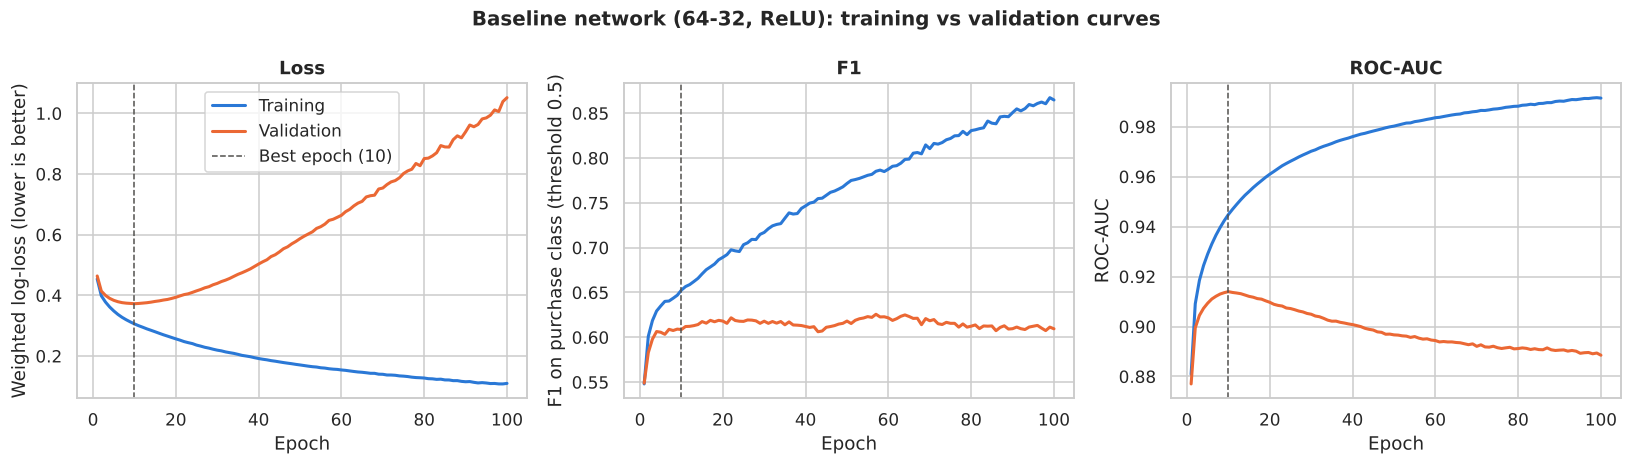

In [5]:
BASE = dict(hidden=(64, 32), activation="relu", alpha=1e-4, lr=1e-3, batch_size=128, class_weight="balanced")
A, B = DATA[False]
base_model, base_hist, base_best = train_mlp(A, y_train, B, y_val, **BASE, max_epochs=100, early_stop=False)

b = base_hist
print(f"Best validation-loss epoch: {base_best}")
print(f"  at best epoch : train loss {b.loc[base_best-1,'train_loss']:.4f} | val loss {b.loc[base_best-1,'val_loss']:.4f} "
      f"| train F1 {b.loc[base_best-1,'train_f1']:.4f} | val F1 {b.loc[base_best-1,'val_f1']:.4f}")
print(f"  at epoch 100  : train loss {b.iloc[-1]['train_loss']:.4f} | val loss {b.iloc[-1]['val_loss']:.4f} "
      f"| train F1 {b.iloc[-1]['train_f1']:.4f} | val F1 {b.iloc[-1]['val_f1']:.4f}")
print(f"  at epoch 100  : train AUC {b.iloc[-1]['train_auc']:.4f} | val AUC {b.iloc[-1]['val_auc']:.4f}")

plot_curves(base_hist, base_best, "Baseline network (64-32, ReLU): training vs validation curves",
            "../plots/fig11_nn_baseline_curves.png")

## 5. Hyperparameter tuning

Random search: 60 configurations x 3 seeds, scored on validation F1.

In [6]:
SEARCH_CSV = "../data/stage3_nn_search_results.csv"
REFINE_CSV = "../data/stage3_nn_refine_results.csv"
RERUN = False

HIDDEN = [(32,), (64,), (128,), (64, 32), (128, 64), (128, 64, 32), (256, 128)]
rng = np.random.RandomState(RANDOM_STATE)
configs = [dict(hidden=HIDDEN[rng.randint(len(HIDDEN))],
                activation=["relu", "tanh"][rng.randint(2)],
                alpha=float(10 ** rng.uniform(-5, -1)),
                lr=float(10 ** rng.uniform(np.log10(3e-4), -2)),
                batch_size=int([64, 128, 256, 512][rng.randint(4)]),
                class_weight=["balanced", "sqrt", "none"][rng.randint(3)],
                log_skewed=bool(rng.randint(2)))
           for _ in range(60)]

def run_cfg(cfg, seed, max_epochs=150):
    A, B = DATA[cfg["log_skewed"]]
    kw = {k: v for k, v in cfg.items() if k != "log_skewed"}
    m, h, be = train_mlp(A, y_train, B, y_val, seed=seed, max_epochs=max_epochs, **kw)
    r = h.loc[be - 1]
    return dict(best_epoch=be, train_loss=r["train_loss"], val_loss=r["val_loss"],
                **metrics(y_val, m.predict_proba(B)[:, 1]))

if os.path.exists(SEARCH_CSV) and not RERUN:
    search = pd.read_csv(SEARCH_CSV)
else:
    t0 = time.time()
    jobs = [(i, s) for i in range(len(configs)) for s in range(3)]
    res = Parallel(n_jobs=2)(delayed(run_cfg)(configs[i], 100 + s) for i, s in jobs)
    search = pd.DataFrame([dict(config_id=i, seed=s, **{k: (str(v) if k == "hidden" else v) for k, v in configs[i].items()}, **r)
                           for (i, s), r in zip(jobs, res)])
    search.to_csv(SEARCH_CSV, index=False)
    print(f"Search finished in {time.time() - t0:.0f}s")

by_cfg = (search.groupby("config_id")
          .agg(hidden=("hidden", "first"), activation=("activation", "first"), alpha=("alpha", "first"),
               lr=("lr", "first"), batch=("batch_size", "first"), weights=("class_weight", "first"),
               log1p=("log_skewed", "first"), val_F1=("F1", "mean"), val_AUC=("ROC-AUC", "mean"),
               val_loss=("val_loss", "mean"), best_epoch=("best_epoch", "mean"))
          .sort_values("val_F1", ascending=False))
print(by_cfg.head(10).round(4).to_string())

Search finished in 273s
                  hidden activation   alpha      lr  batch weights  log1p  val_F1  val_AUC  val_loss  best_epoch
config_id                                                                                                       
10         (128, 64, 32)       relu  0.0756  0.0045    128    sqrt   True  0.6681   0.9297    0.3097      2.0000
9                  (64,)       tanh  0.0105  0.0013    128    sqrt   True  0.6664   0.9311    0.3050     43.0000
39                 (32,)       tanh  0.0013  0.0007    512    sqrt   True  0.6663   0.9289    0.3103    144.6667
46                 (32,)       tanh  0.0000  0.0011    256    sqrt   True  0.6644   0.9294    0.3097     58.0000
33                (128,)       relu  0.0082  0.0011    512    sqrt   True  0.6622   0.9296    0.3088     34.3333
30                 (32,)       tanh  0.0000  0.0025    128    sqrt  False  0.6615   0.9174    0.3334     26.0000
43                (128,)       relu  0.0000  0.0005    128    sqrt   Tru

weights
balanced    0.6291
none        0.6359
sqrt        0.6590
log1p
False    0.6330
True     0.6504

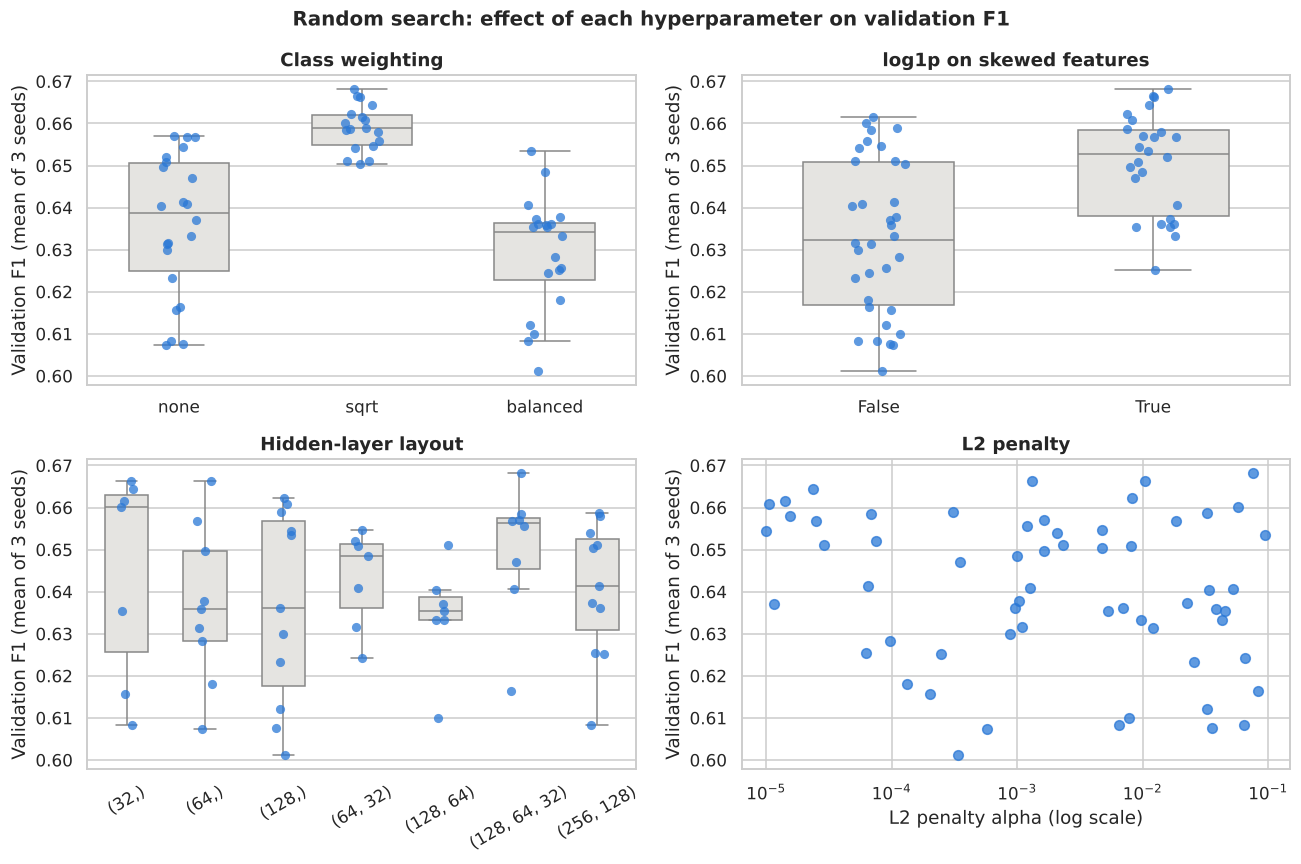

In [7]:
order_hidden = [str(h) for h in HIDDEN]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
def strip(ax, col, order, title):
    sns.boxplot(data=by_cfg, x=col, y="val_F1", order=order, color="#e6e5e0", showfliers=False, width=0.55, ax=ax)
    sns.stripplot(data=by_cfg, x=col, y="val_F1", order=order, color=TRAIN_C, alpha=0.75, size=6, ax=ax)
    ax.set_title(title, fontweight="bold"); ax.set_ylabel("Validation F1 (mean of 3 seeds)"); ax.set_xlabel("")
strip(axes[0, 0], "weights", ["none", "sqrt", "balanced"], "Class weighting")
strip(axes[0, 1], "log1p", [False, True], "log1p on skewed features")
strip(axes[1, 0], "hidden", order_hidden, "Hidden-layer layout")
axes[1, 0].tick_params(axis="x", labelrotation=30)
ax = axes[1, 1]
ax.scatter(by_cfg["alpha"], by_cfg["val_F1"], color=TRAIN_C, alpha=0.75, s=40)
ax.set_xscale("log"); ax.set_xlabel("L2 penalty alpha (log scale)"); ax.set_ylabel("Validation F1 (mean of 3 seeds)")
ax.set_title("L2 penalty", fontweight="bold")
fig.suptitle("Random search: effect of each hyperparameter on validation F1", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../plots/fig13_nn_hyperparameter_effects.png", dpi=300)
plt.show()

print(by_cfg.groupby("weights")["val_F1"].mean().round(4).to_string())
print(by_cfg.groupby("log1p")["val_F1"].mean().round(4).to_string())

Re-run the 8 best configurations with 5 new seeds and pick the best.

In [8]:
def cfg_from_row(r):
    return dict(hidden=ast.literal_eval(r["hidden"]), activation=r["activation"], alpha=float(r["alpha"]),
                lr=float(r["lr"]), batch_size=int(r["batch_size"]), class_weight=r["class_weight"],
                log_skewed=bool(r["log_skewed"]))

first_rows = search.drop_duplicates("config_id").set_index("config_id")
top_ids = by_cfg.index[:8].tolist()

if os.path.exists(REFINE_CSV) and not RERUN:
    refine = pd.read_csv(REFINE_CSV)
else:
    jobs = [(i, s) for i in top_ids for s in range(200, 205)]
    res = Parallel(n_jobs=2)(delayed(run_cfg)(cfg_from_row(first_rows.loc[i]), s, 200) for i, s in jobs)
    refine = pd.DataFrame([dict(config_id=i, seed=s, **r) for (i, s), r in zip(jobs, res)])
    refine.to_csv(REFINE_CSV, index=False)

ref = (refine.groupby("config_id")
       .agg(F1=("F1", "mean"), F1_sd=("F1", "std"), AUC=("ROC-AUC", "mean"), Precision=("Precision", "mean"),
            Recall=("Recall", "mean"), val_loss=("val_loss", "mean"), best_epoch=("best_epoch", "median"))
       .sort_values("F1", ascending=False))
print(ref.round(4).to_string())

FINAL_ID = ref.index[0]
FINAL = cfg_from_row(first_rows.loc[FINAL_ID])
FINAL_LOG = FINAL.pop("log_skewed")
FINAL_EPOCHS = int(ref.loc[FINAL_ID, "best_epoch"])
print("\nSelected configuration:", {**FINAL, "log1p": FINAL_LOG})
print("Median best epoch over 5 seeds:", FINAL_EPOCHS)

               F1   F1_sd     AUC  Precision  Recall  val_loss  best_epoch
config_id                                                                 
9          0.6658  0.0081  0.9302     0.6075  0.7378    0.3078        41.0
39         0.6634  0.0089  0.9284     0.6129  0.7231    0.3107       162.0
10         0.6625  0.0069  0.9279     0.5847  0.7685    0.3131         3.0
46         0.6613  0.0072  0.9286     0.6032  0.7322    0.3103        65.0
43         0.6590  0.0030  0.9299     0.6098  0.7175    0.3080        26.0
33         0.6587  0.0036  0.9294     0.6109  0.7147    0.3094        32.0
30         0.6559  0.0124  0.9157     0.6129  0.7070    0.3372        24.0
50         0.6539  0.0094  0.9184     0.6178  0.6951    0.3327        18.0

Selected configuration: {'hidden': (64,), 'activation': 'tanh', 'alpha': 0.010506199451597035, 'lr': 0.0013322388661249464, 'batch_size': 128, 'class_weight': 'sqrt', 'log1p': True}
Median best epoch over 5 seeds: 41

## 6. Final network: training vs validation curves

Epochs run: 56 | best epoch: 41
  at best epoch: train loss 0.2697 | val loss 0.3067 | train F1 0.7103 | val F1 0.6636
  at best epoch: train AUC 0.9466 | val AUC 0.9304
  at last epoch: train loss 0.2585 | val loss 0.3073

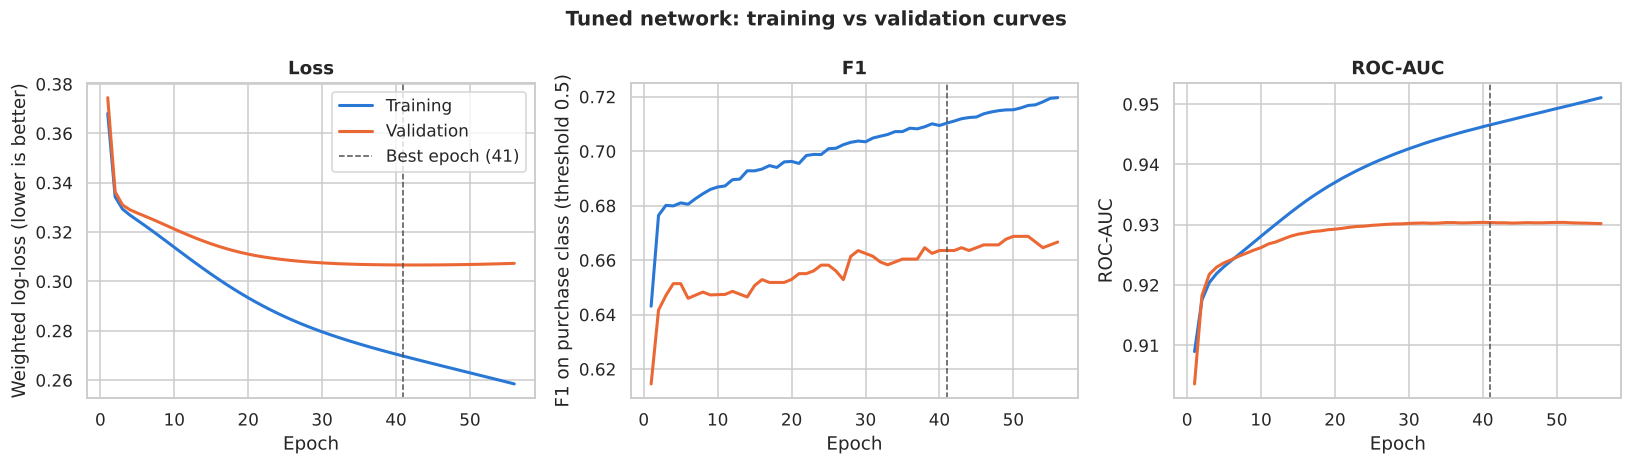

In [9]:
A, B = DATA[FINAL_LOG]
final_mlp, final_hist, final_best = train_mlp(A, y_train, B, y_val, **FINAL, max_epochs=200, patience=15, seed=RANDOM_STATE)
h = final_hist
print(f"Epochs run: {len(h)} | best epoch: {final_best}")
print(f"  at best epoch: train loss {h.loc[final_best-1,'train_loss']:.4f} | val loss {h.loc[final_best-1,'val_loss']:.4f} "
      f"| train F1 {h.loc[final_best-1,'train_f1']:.4f} | val F1 {h.loc[final_best-1,'val_f1']:.4f}")
print(f"  at best epoch: train AUC {h.loc[final_best-1,'train_auc']:.4f} | val AUC {h.loc[final_best-1,'val_auc']:.4f}")
print(f"  at last epoch: train loss {h.iloc[-1]['train_loss']:.4f} | val loss {h.iloc[-1]['val_loss']:.4f}")

plot_curves(final_hist, final_best, "Tuned network: training vs validation curves", "../plots/fig12_nn_tuned_curves.png")

### Capacity and regularisation sweeps

alpha sweep
         train_loss  val_loss  train_f1  val_f1  best_epoch
value                                                      
0.00001      0.2759    0.3095    0.7068  0.6601     29.3333
0.00010      0.2749    0.3094    0.7075  0.6601     30.3333
0.00100      0.2731    0.3086    0.7088  0.6630     32.3333
0.01000      0.2701    0.3071    0.7110  0.6658     38.6667
0.10000      0.2712    0.3035    0.7081  0.6691     98.6667
1.00000      0.3110    0.3165    0.6805  0.6585    198.6667
3.00000      0.3396    0.3411    0.6744  0.6553     68.6667

width sweep
       train_loss  val_loss  train_f1  val_f1  best_epoch
value                                                    
4          0.2789    0.3052    0.7024  0.6571     81.3333
8          0.2741    0.3044    0.7074  0.6620     70.0000
16         0.2734    0.3071    0.7107  0.6621     47.3333
32         0.2745    0.3071    0.7076  0.6635     37.0000
64         0.2703    0.3071    0.7108  0.6658     38.6667
128        0.2721    0.3080  

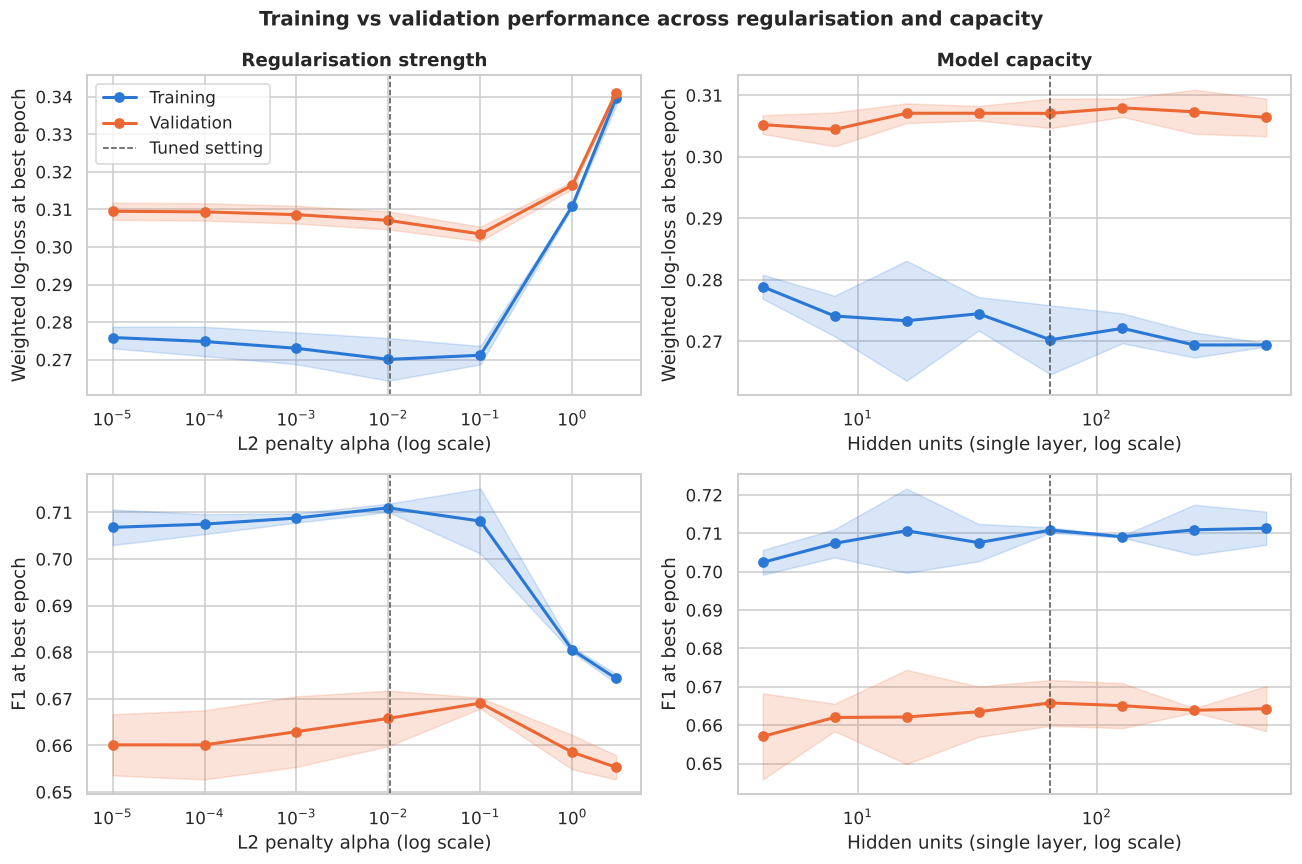

In [10]:
def sweep(param, values, seeds=(300, 301, 302)):
    rows = []
    for v in values:
        for s in seeds:
            cfg = dict(FINAL)
            if param == "width":
                cfg["hidden"] = (v,)
            else:
                cfg[param] = v
            m, hh, be = train_mlp(A, y_train, B, y_val, seed=s, max_epochs=200, **cfg)
            r = hh.loc[be - 1]
            rows.append(dict(value=v, seed=s, best_epoch=be, train_loss=r["train_loss"], val_loss=r["val_loss"],
                             train_f1=r["train_f1"], val_f1=r["val_f1"]))
    return pd.DataFrame(rows)

alpha_vals = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 3.0]
width_vals = [4, 8, 16, 32, 64, 128, 256, 512]
sw_alpha, sw_width = sweep("alpha", alpha_vals), sweep("width", width_vals)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, (sw, xlabel, chosen, logx) in enumerate([(sw_alpha, "L2 penalty alpha (log scale)", FINAL["alpha"], True),
                                                    (sw_width, "Hidden units (single layer, log scale)", FINAL["hidden"][0], True)]):
    for row, (key, ylab) in enumerate([("loss", "Weighted log-loss at best epoch"), ("f1", "F1 at best epoch")]):
        ax = axes[row, col]
        for split, color, lab in [("train", TRAIN_C, "Training"), ("val", VAL_C, "Validation")]:
            g = sw.groupby("value")[f"{split}_{key}"].agg(["mean", "std"])
            ax.plot(g.index, g["mean"], color=color, lw=2, marker="o", ms=6, label=lab)
            ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], color=color, alpha=0.18)
        ax.axvline(chosen, color=MARK_C, ls="--", lw=1, label="Tuned setting")
        ax.set_xscale("log"); ax.set_xlabel(xlabel); ax.set_ylabel(ylab)
axes[0, 0].legend(loc="best")
axes[0, 0].set_title("Regularisation strength", fontweight="bold"); axes[0, 1].set_title("Model capacity", fontweight="bold")
fig.suptitle("Training vs validation performance across regularisation and capacity", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../plots/fig14_nn_capacity_regularisation.png", dpi=300)
plt.show()

summ = lambda sw: sw.groupby("value")[["train_loss", "val_loss", "train_f1", "val_f1", "best_epoch"]].mean().round(4)
print("alpha sweep"); print(summ(sw_alpha).to_string())
print("\nwidth sweep"); print(summ(sw_width).to_string())

## 7. Validation and 10-fold CV results

In [11]:
pva = final_mlp.predict_proba(B)[:, 1]
val_metrics = metrics(y_val, pva)
seed_rows = refine[refine["config_id"] == FINAL_ID]
print("Validation metrics (seed 42):")
print(pd.Series(val_metrics).round(4).to_string())
print("\nValidation metrics over the 5 confirmation seeds (mean ± std):")
for k in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    print(f"  {k:10s} {seed_rows[k].mean():.4f} ± {seed_rows[k].std():.4f}")

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
fold_rows = []
for tr_idx, te_idx in cv10.split(X_train, y_train):
    prep = make_preprocessor(FINAL_LOG).fit(X_train.iloc[tr_idx])
    m = fit_fixed(prep.transform(X_train.iloc[tr_idx]), y_train[tr_idx], FINAL_EPOCHS, **FINAL)
    fold_rows.append(metrics(y_train[te_idx], m.predict_proba(prep.transform(X_train.iloc[te_idx]))[:, 1]))
cv_df = pd.DataFrame(fold_rows)
print(f"\n10-fold CV on the training set ({FINAL_EPOCHS} epochs per fold):")
for k in cv_df.columns:
    print(f"  {k:10s} {cv_df[k].mean():.4f} ± {cv_df[k].std(ddof=0):.4f}")

Validation metrics (seed 42):
Accuracy     0.8820
Precision    0.5983
Recall       0.7448
F1           0.6636
ROC-AUC      0.9304

Validation metrics over the 5 confirmation seeds (mean ± std):
  Accuracy   0.8843 ± 0.0047
  Precision  0.6075 ± 0.0177
  Recall     0.7378 ± 0.0267
  F1         0.6658 ± 0.0081
  ROC-AUC    0.9302 ± 0.0010

10-fold CV on the training set (41 epochs per fold):
  Accuracy   0.8914 ± 0.0074
  Precision  0.6309 ± 0.0265
  Recall     0.7417 ± 0.0454
  F1         0.6808 ± 0.0226
  ROC-AUC    0.9289 ± 0.0077

## 8. Save model and results

In [12]:
nn_pipeline = Pipeline([("prep", PREP[FINAL_LOG]), ("clf", final_mlp)])
joblib.dump(nn_pipeline, "../models/neural_network_tuned.joblib", compress=3)
final_hist.to_csv("../data/stage3_nn_history.csv", index=False)
base_hist.to_csv("../data/stage3_nn_baseline_history.csv", index=False)

cv_table = pd.DataFrame({"Neural Network": {k.lower().replace("-", "_"): f"{cv_df[k].mean():.4f} ± {cv_df[k].std(ddof=0):.4f}"
                                            for k in cv_df.columns}}).T
val_table = pd.DataFrame({"Neural Network": val_metrics}).T.round(4)
summary = pd.concat({"CV (10-fold, train)": cv_table, "Validation": val_table.astype(str)}, axis=1)
summary.to_csv("../data/stage3_nn_results_summary.csv")
print(summary.T.to_string())

reloaded = joblib.load("../models/neural_network_tuned.joblib")
assert np.allclose(reloaded.predict_proba(X_val)[:, 1], pva), "saved pipeline does not match"
print("\nSaved pipeline reloads and reproduces the validation predictions.")

                                Neural Network
CV (10-fold, train) accuracy   0.8914 ± 0.0074
                    precision  0.6309 ± 0.0265
                    recall     0.7417 ± 0.0454
                    f1         0.6808 ± 0.0226
                    roc_auc    0.9289 ± 0.0077
Validation          Accuracy             0.882
                    Precision           0.5983
                    Recall              0.7448
                    F1                  0.6636
                    ROC-AUC             0.9304

Saved pipeline reloads and reproduces the validation predictions.

## 9. Summary

* The untuned baseline overfits after about 10 epochs: validation loss rises from 0.37 to 1.05 while training loss keeps falling.
* The tuned network (1 hidden layer of 64 tanh units, alpha 0.0105, learning rate 0.0013, batch size 128, sqrt class weights, log1p) is best at epoch 41, with a train/validation loss gap of 0.037.
* Class weighting and the log1p transform mattered most. Width (4 to 512 units) and alpha up to 0.1 made little difference; alpha of 1 or more underfits.
* Validation F1 0.664 and ROC-AUC 0.930; 10-fold CV F1 0.681 ± 0.023. This is close to the Random Forest (0.669 / 0.930) and better than the SVM (0.633 / 0.902).
* The test set is not used here; the final comparison is done in the evaluation stage.